# Análisis Factorial: indicadores estatales de la ENIGH 2024

Cuaderno del **Capítulo 3** de las notas. Construye seis indicadores por entidad federativa a partir del microdato de la ENIGH 2024 (tabla `concentradohogar`, INEGI) y estima un modelo factorial con el módulo `utils/factorial.py`, escrito con `numpy` y `scipy` para que cada paso coincida con las fórmulas de las notas.

**Contenido**
1. Construcción de la base de datos (32 entidades × 6 indicadores)
2. Adecuación: Bartlett, KMO y MSA
3. Un factor y tres variables: solución cerrada
4. Estimación: componentes principales, ejes principales y máxima verosimilitud
5. Rotación: varimax y promax
6. Puntuaciones factoriales (regresión y Bartlett)
7. Confiabilidad: alfa de Cronbach y omega de McDonald
8. Autoevaluación

**Cómo usar este cuaderno.** Después de los resultados principales hay celdas **Lea la salida** con espacios `____` para completar, con el mismo formato que el quiz y el examen. Complételas *antes* de abrir la respuesta. Las celdas **Error común** muestran a propósito un análisis equivocado. Al final hay una autoevaluación.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True, precision=3)
pd.set_option("display.precision", 3)
AZUL, NARANJA, VERDE, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#d9d8d4", "figure.dpi": 110})
import sys, zipfile
sys.path.insert(0, "../../utils")
import factorial as fa

## 1. Construcción de la base de datos

Cada hogar se pondera con su factor de expansión (`factor`). Las proporciones son cocientes de totales ponderados.

In [2]:
ENTIDADES = ["Aguascalientes", "Baja California", "Baja California Sur", "Campeche", "Coahuila",
             "Colima", "Chiapas", "Chihuahua", "Ciudad de México", "Durango", "Guanajuato",
             "Guerrero", "Hidalgo", "Jalisco", "México", "Michoacán", "Morelos", "Nayarit",
             "Nuevo León", "Oaxaca", "Puebla", "Querétaro", "Quintana Roo", "San Luis Potosí",
             "Sinaloa", "Sonora", "Tabasco", "Tamaulipas", "Tlaxcala", "Veracruz", "Yucatán",
             "Zacatecas"]
with zipfile.ZipFile("../03 ENIGH/enigh2024_ns_concentradohogar_csv.zip") as z:
    hog = pd.read_csv(z.open("concentradohogar.csv"), low_memory=False, dtype={"ubica_geo": str})
g = hog.ubica_geo.str.zfill(5).str[:2].astype(int)
w = hog.factor
media = lambda x: (x * w).groupby(g).sum() / w.groupby(g).sum()
cociente = lambda num, den: (num * w).groupby(g).sum() / (den * w).groupby(g).sum()

X = pd.DataFrame({
    "ing_pc": np.log(media(hog.ing_cor / hog.tot_integ)),   # log ingreso corriente trimestral pc
    "edu_jefe": media(hog.educa_jefe),                       # escala 1-11 de la ENIGH
    "menores_sh": cociente(hog.menores, hog.tot_integ),      # menores de 12 años
    "perceptores": cociente(hog.percep_ing, hog.tot_integ),
    "mayores65_sh": cociente(hog.p65mas, hog.tot_integ),
    "trab_sh": cociente(hog.ingtrab, hog.ing_cor),
})
X.index = ENTIDADES
X.index.name = "entidad"
X = X.round(4)          # se trabaja con los valores que se guardan, para coincidir con las notas
X.to_csv("enigh2024_entidades.csv")
print(hog.shape[0], "hogares")
X.round(3)

91414 hogares


,ing_pc,edu_jefe,menores_sh,perceptores,mayores65_sh,trab_sh
entidad,,,,,,
Aguascalientes,10.364,6.702,0.193,0.648,0.088,0.656
Baja California,10.551,6.599,0.166,0.623,0.089,0.707
Baja California Sur,10.607,6.844,0.172,0.681,0.066,0.694
Campeche,10.037,6.080,0.181,0.637,0.090,0.644
Coahuila,10.346,6.722,0.184,0.622,0.089,0.707
Colima,10.462,6.536,0.158,0.725,0.104,0.644
Chiapas,9.500,5.082,0.221,0.585,0.084,0.669
Chihuahua,10.440,6.458,0.176,0.651,0.091,0.673
Ciudad de México,10.781,7.434,0.107,0.796,0.144,0.610


In [3]:
R = X.corr().values
n, p = X.shape
pd.DataFrame(R, index=X.columns, columns=X.columns).round(3)

,ing_pc,edu_jefe,menores_sh,perceptores,mayores65_sh,trab_sh
ing_pc,1.000,0.909,-0.668,0.545,-0.164,0.170
edu_jefe,0.909,1.000,-0.669,0.499,-0.201,0.274
menores_sh,-0.668,-0.669,1.000,-0.711,-0.351,0.137
perceptores,0.545,0.499,-0.711,1.000,0.363,-0.362
mayores65_sh,-0.164,-0.201,-0.351,0.363,1.000,-0.773
trab_sh,0.170,0.274,0.137,-0.362,-0.773,1.000


### Lea la salida

1. La correlación más alta es entre `____` y `____` (`____`).
2. `mayores65_sh` y `trab_sh` tienen correlación `____`, pero las dos se relacionan `____` (mucho / poco) con el ingreso.
3. Con estos bloques de correlaciones, ¿cuántos factores esperaría antes de estimar? `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. `ing_pc` y `edu_jefe` (0.909).
2. −0.773; poco (−0.164 y 0.170 con el ingreso).
3. Dos: uno socioeconómico (ingreso, escolaridad, menores y perceptores) y otro de estructura de edad (adultos mayores y peso del ingreso laboral).

</details>

## 2. Adecuación de los datos

In [4]:
chi2, gl, pval = fa.bartlett_esfericidad(R, n)
print(f"Bartlett: |R| = {np.linalg.det(R):.4f}, χ² = {chi2:.1f}, gl = {gl:.0f}, p = {pval:.1e}")
kmo, msa = fa.kmo(R)
print(f"KMO = {kmo:.3f}")
print(pd.Series(msa, index=X.columns, name="MSA").round(3))
print("Correlaciones parciales:\n", pd.DataFrame(fa.correlaciones_parciales(R), index=X.columns, columns=X.columns).round(3))

Bartlett: |R| = 0.0064, χ² = 142.2, gl = 15, p = 8.4e-23
KMO = 0.657
ing_pc          0.689
edu_jefe        0.705
menores_sh      0.694
perceptores     0.807
mayores65_sh    0.509
trab_sh         0.510
Name: MSA, dtype: float64
Correlaciones parciales:
               ing_pc  edu_jefe  menores_sh  perceptores  mayores65_sh  trab_sh
ing_pc         1.000     0.749      -0.194        0.110        -0.270   -0.222
edu_jefe       0.749     1.000      -0.253        0.063        -0.057    0.232
menores_sh    -0.194    -0.253       1.000       -0.393        -0.573   -0.309
perceptores    0.110     0.063      -0.393        1.000        -0.068   -0.372
mayores65_sh  -0.270    -0.057      -0.573       -0.068         1.000   -0.692
trab_sh       -0.222     0.232      -0.309       -0.372        -0.692    1.000


### Lea la salida

1. Bartlett: $p =$ `____` ⇒ se rechaza que `____`.
2. KMO = `____`, que en la escala de Kaiser es `____`. Las MSA más bajas son las de `____` y `____` (≈ `____`).
3. La correlación parcial entre ingreso y escolaridad es `____`: aun descontando las otras cuatro variables, siguen `____`.
4. Decisión: `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. $8.4 \times 10^{-23}$ ⇒ se rechaza que $\mathbf{R} = \mathbf{I}$ (que las variables no estén correlacionadas).
2. 0.657, "mediocre" (entre 0.60 y 0.70), que es aceptable. Las más bajas son `mayores65_sh` y `trab_sh` (0.51), apenas arriba del mínimo de 0.50.
3. 0.749: siguen muy asociadas; comparten algo más que los factores comunes (las dos miden recursos del hogar).
4. Proceder con el análisis factorial, con cautela y vigilando esas dos variables. Bartlett por sí solo no basta: con variables correlacionadas casi siempre rechaza; el KMO es el que decide.

</details>

## 3. Un factor y tres variables: solución cerrada

$\ell_1^2 = r_{12}r_{13}/r_{23}$, $\ell_2^2 = r_{12}r_{23}/r_{13}$, $\ell_3^2 = r_{13}r_{23}/r_{12}$.

In [5]:
r12, r13, r23 = R[0, 1], R[0, 2], R[1, 2]          # ingreso, escolaridad, menores
l2 = np.array([r12 * r13 / r23, r12 * r23 / r13, r13 * r23 / r12])
ell = np.sqrt(l2) * np.array([1, 1, -1])
print("Cargas:", ell.round(3), "| unicidades:", (1 - l2).round(3))
print("ℓℓ' reproduce las correlaciones:\n", np.outer(ell, ell).round(3))

Cargas: [ 0.953  0.954 -0.701] | unicidades: [0.092 0.089 0.508]
ℓℓ' reproduce las correlaciones:
 [[ 0.908  0.909 -0.668]
 [ 0.909  0.911 -0.669]
 [-0.668 -0.669  0.492]]


### Lea la salida

1. Las cargas son `____`, `____` y `____`; la de `menores_sh` es negativa porque `____`.
2. La unicidad de `menores_sh` es `____`: la mitad de su varianza `____`.
3. ¿Es un caso de Heywood? `____`, porque `____`.
4. $\boldsymbol{\ell}\boldsymbol{\ell}'$ reproduce exactamente las correlaciones porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 0.953, 0.954 y −0.701. Más menores por integrante significa más dependientes y peores condiciones del hogar.
2. 0.508: la mitad de su varianza no la explica el factor común (es específica o error de medición).
3. No: las tres comunalidades (0.908, 0.911 y 0.492) son menores que 1 y las unicidades son positivas.
4. Con $p = 3$ y $m = 1$, $\nu = 0$: el modelo tiene tantos parámetros como correlaciones y las reproduce sin error.

</details>

## 4. Estimación con tres métodos

In [6]:
lam = np.linalg.eigvalsh(R)[::-1]
print("Eigenvalores:", lam.round(3), "| acumulada:", (lam.cumsum() / p).round(3))
Lpc = fa.fa_componentes(R, 2); Lpc *= np.sign(Lpc[0])
Lpa, it = fa.fa_ejes_principales(R, 2); Lpa *= np.sign(Lpa[0])
L, psi, F = fa.fa_maxima_verosimilitud(R, 2); L *= np.sign(L[0])
tabla = pd.DataFrame(np.c_[Lpc, (Lpc**2).sum(1), Lpa, (Lpa**2).sum(1), L, 1 - psi], index=X.columns,
                     columns=pd.MultiIndex.from_product([["Componentes", "Ejes principales", "Máx. verosimilitud"],
                                                         ["l1", "l2", "h2"]]))
print("Ejes principales: iteraciones =", it)
tabla.round(3)

Eigenvalores: [3.025 2.123 0.359 0.296 0.118 0.08 ] | acumulada: [0.504 0.858 0.918 0.967 0.987 1.   ]
Ejes principales: iteraciones = 67


Componentes               Ejes principales                \
                      l1     l2     h2               l1     l2     h2   
ing_pc             0.882  0.344  0.896            0.883  0.290  0.864   
edu_jefe           0.864  0.416  0.920            0.887  0.372  0.926   
menores_sh        -0.897  0.165  0.833           -0.846  0.206  0.758   
perceptores        0.811 -0.345  0.777            0.728 -0.346  0.650   
mayores65_sh       0.175 -0.919  0.875            0.136 -0.911  0.848   
trab_sh           -0.081  0.917  0.848           -0.043  0.832  0.694   

             Máx. verosimilitud                
                             l1     l2     h2  
ing_pc                    0.942  0.033  0.888  
edu_jefe                  0.963 -0.020  0.929  
menores_sh               -0.705 -0.513  0.760  
perceptores               0.547  0.546  0.597  
mayores65_sh             -0.196  0.923  0.891  
trab_sh                   0.252 -0.776  0.666

### Lea la salida

1. Eigenvalores de $\mathbf{R}$ mayores que 1: `____` ⇒ `____` factores, que explican `____` %.
2. La comunalidad de `trab_sh` es `____` con componentes y `____` con máxima verosimilitud. El método de componentes da comunalidades más altas porque `____`.
3. En la solución de máxima verosimilitud sin rotar, `perceptores` carga `____` en F1 y `____` en F2: está `____`. Eso sugiere `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 3.025 y 2.123 ⇒ dos factores, que explican el 85.8 %.
2. 0.848 contra 0.666. El método de componentes no separa la varianza única: atribuye a los factores parte de la varianza específica y del error.
3. 0.547 y 0.546: está repartida entre los dos factores. Sugiere rotar para buscar una estructura simple.

</details>

In [7]:
for m in [1, 2]:
    Lm, psim, Fm = fa.fa_maxima_verosimilitud(R, m)
    est, glm, pm = fa.prueba_ajuste_mv(Fm, n, p, m)
    print(f"m = {m}: χ² = {est:.2f}, gl = {glm:.0f}, p = {pm:.3g}")
res = R - L @ L.T - np.diag(psi)
print("Máximo residuo |r - σ̂| con m = 2:", np.abs(res).max().round(3))

m = 1: χ² = 61.44, gl = 9, p = 7.06e-10
m = 2: χ² = 8.68, gl = 4, p = 0.0696
Máximo residuo |r - σ̂| con m = 2: 0.083


### Lea la salida

1. Con $m = 1$: $\chi^2 =$ `____`, $p =$ `____` ⇒ `____`.
2. Con $m = 2$: $p =$ `____` ⇒ `____` al 5 %.
3. Grados de libertad con $m = 2$: $\nu = [(p - m)^2 - (p + m)]/2 =$ `____`.
4. El residuo máximo es `____`: `____` (grande / pequeño) frente a las correlaciones originales.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 61.44, $p = 7 \times 10^{-10}$ ⇒ un factor no basta.
2. 0.070 ⇒ no se rechaza, aunque por poco.
3. $[(6 - 2)^2 - (6 + 2)]/2 = (16 - 8)/2 = 4$.
4. 0.083: pequeño, comparado con correlaciones de hasta 0.909.

</details>

## 5. Rotación

In [8]:
Lv, T = fa.varimax(L)
print("Matriz de rotación T:\n", T.round(3), "| ángulo =", np.degrees(np.arctan2(T[1, 0], T[0, 0])).round(1), "grados")
print(pd.DataFrame(np.c_[Lv, (Lv**2).sum(1)], index=X.columns, columns=["F1", "F2", "h2"]).round(3))
print("Criterio varimax: sin rotar", fa.varimax_criterio(L).round(3), "| rotada", fa.varimax_criterio(Lv).round(3))
patron, Phi = fa.promax(L)
print("Promax, correlación entre factores:", Phi[0, 1].round(3))

Matriz de rotación T:
 [[ 0.966 -0.257]
 [ 0.257  0.966]] | ángulo = 14.9 grados
                 F1     F2     h2
ing_pc        0.919 -0.210  0.888
edu_jefe      0.926 -0.268  0.929
menores_sh   -0.813 -0.314  0.760
perceptores   0.669  0.386  0.597
mayores65_sh  0.048  0.943  0.891
trab_sh       0.044 -0.815  0.666
Criterio varimax: sin rotar 0.293 | rotada 0.345
Promax, correlación entre factores: 0.155


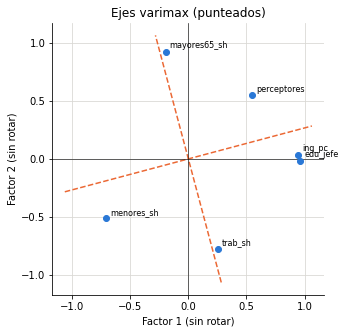

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(L[:, 0], L[:, 1], color=AZUL, zorder=3)
for j, v in enumerate(X.columns):
    ax.annotate(v, (L[j, 0], L[j, 1]), xytext=(4, 4), textcoords="offset points", fontsize=8)
for c in range(2):
    ax.plot([-1.1 * T[0, c], 1.1 * T[0, c]], [-1.1 * T[1, c], 1.1 * T[1, c]], color=NARANJA, ls="--")
ax.axhline(0, color=TINTA, lw=0.6); ax.axvline(0, color=TINTA, lw=0.6)
ax.set_aspect("equal"); ax.set_xlabel("Factor 1 (sin rotar)"); ax.set_ylabel("Factor 2 (sin rotar)")
ax.set_title("Ejes varimax (punteados)"); plt.show()

### Lea la salida

1. Varimax gira los ejes `____` grados.
2. Las comunalidades rotadas (`h2`) son `____` (iguales / distintas) a las de máxima verosimilitud sin rotar.
3. Después de rotar, F1 tiene cargas altas en `____` ⇒ F1 es `____`. F2 tiene cargas altas en `____` (positiva) y `____` (negativa) ⇒ F2 es `____`.
4. Con promax, la correlación entre factores es `____`, lo que `____` (justifica / no justifica) quedarse con factores ortogonales.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 14.9 grados.
2. Iguales (0.888, 0.929, 0.760, …): rotar no cambia el ajuste.
3. F1: `ing_pc` (0.919), `edu_jefe` (0.926), `menores_sh` (−0.813) y `perceptores` (0.669) ⇒ nivel socioeconómico. F2: `mayores65_sh` (0.943) y `trab_sh` (−0.815) ⇒ envejecimiento: más adultos mayores y menor peso del ingreso laboral.
4. 0.155: pequeña, así que la solución ortogonal es razonable.

</details>

### Error común: creer que la rotación mejora el ajuste

In [10]:
print("¿Cambia LL' al rotar?", not np.allclose(L @ L.T, Lv @ Lv.T))
print("Máximo residuo sin rotar:", np.abs(R - L @ L.T - np.diag(psi)).max().round(3),
      "| rotada:", np.abs(R - Lv @ Lv.T - np.diag(psi)).max().round(3))

¿Cambia LL' al rotar? False
Máximo residuo sin rotar: 0.083 | rotada: 0.083


### Lea la salida

La rotación `____` (cambia / no cambia) el ajuste, porque `____`. Sirve sólo para `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

No cambia: $\mathbf{L}_v\mathbf{L}_v' = \mathbf{L}\mathbf{T}\mathbf{T}'\mathbf{L}' = \mathbf{L}\mathbf{L}'$, porque $\mathbf{T}$ es ortogonal; los residuos son idénticos. Sirve sólo para interpretar: elige, entre soluciones con el mismo ajuste, la de estructura más simple.

</details>

### Lo mismo con `sklearn`

`sklearn.decomposition.FactorAnalysis` estima por máxima verosimilitud y puede rotar con varimax. Su tolerancia por omisión (`tol=1e-2`) es gruesa, así que se ajusta para que converja.

In [11]:
from sklearn.decomposition import FactorAnalysis
Zstd = ((X - X.mean()) / X.std(ddof=0)).values
fa_sk = FactorAnalysis(n_components=2, rotation="varimax", tol=1e-10, max_iter=100_000).fit(Zstd)
L_sk = fa_sk.components_.T                      # components_ tiene una FILA por factor
print(pd.DataFrame(np.c_[L_sk, (L_sk**2).sum(1), fa_sk.noise_variance_, psi], index=X.columns,
                   columns=["F1 sk", "F2 sk", "h2 sk", "psi sk", "psi notas"]).round(3))
L_cruda, _ = fa.varimax(L, normalizar=False)
print("Varimax de utils SIN normalización de Kaiser:\n", L_cruda.round(3))

              F1 sk  F2 sk  h2 sk  psi sk  psi notas
ing_pc       -0.933 -0.133  0.888   0.112      0.112
edu_jefe     -0.945 -0.190  0.929   0.071      0.071
menores_sh    0.784 -0.380  0.760   0.240      0.240
perceptores  -0.635  0.441  0.597   0.403      0.403
mayores65_sh  0.030  0.943  0.891   0.109      0.109
trab_sh      -0.111 -0.809  0.666   0.334      0.334
Varimax de utils SIN normalización de Kaiser:
 [[ 0.933 -0.133]
 [ 0.945 -0.19 ]
 [-0.784 -0.38 ]
 [ 0.635  0.441]
 [-0.03   0.943]
 [ 0.112 -0.809]]


### Lea la salida

1. Las unicidades de `sklearn` (`noise_variance_`) `____` (coinciden / no coinciden) con las de las notas, y las comunalidades `____`.
2. Las cargas rotadas difieren un poco de las de las notas (0.933 contra 0.919 en `ing_pc`) porque `____`. Además, F1 sale con el signo `____`.
3. ¿Cuál de las dos es "la correcta"? `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. Coinciden (es el mismo estimador de máxima verosimilitud), y las comunalidades también.
2. `sklearn` aplica varimax sin la normalización de Kaiser; las notas (como SPSS) normalizan por la comunalidad. La versión sin normalizar de `utils` reproduce las cargas de `sklearn`. F1 sale con el signo opuesto, que es arbitrario.
3. Las dos: son rotaciones distintas de la misma solución, con el mismo ajuste y la misma interpretación. Al reportar, hay que decir qué rotación se usó.

</details>

## 6. Puntuaciones factoriales

In [12]:
Z = ((X - X.mean()) / X.std(ddof=0)).values
Freg = pd.DataFrame(fa.puntuaciones_regresion(Z, R, Lv), index=X.index, columns=["F1", "F2"])
Fbar = pd.DataFrame(fa.puntuaciones_bartlett(Z, Lv, psi), index=X.index, columns=["F1", "F2"])
print("Varianza (regresión):", Freg.var(ddof=0).round(3).tolist(), "= diag(L'R⁻¹L):", np.diag(Lv.T @ np.linalg.solve(R, Lv)).round(3).tolist())
print("Varianza (Bartlett):", Fbar.var(ddof=0).round(3).tolist())
print("Correlación regresión-Bartlett:", [round(np.corrcoef(Freg.iloc[:, j], Fbar.iloc[:, j])[0, 1], 4) for j in range(2)])
Freg.to_csv("enigh2024_puntuaciones.csv")
Freg.sort_values("F1").round(3)

Varianza (regresión): [0.958, 0.923] = diag(L'R⁻¹L): [0.958, 0.923]
Varianza (Bartlett): [1.044, 1.084]
Correlación regresión-Bartlett: [0.9999, 0.9999]


,F1,F2
entidad,,
Chiapas,-2.480,-0.717
Guerrero,-1.731,0.563
Oaxaca,-1.669,1.025
Michoacán,-0.835,0.108
Puebla,-0.802,0.278
Veracruz,-0.788,1.700
Zacatecas,-0.767,0.454
Tlaxcala,-0.546,-0.183
Guanajuato,-0.506,0.185


### Lea la salida

1. La entidad con mayor F1 es `____` (`____`) y la de menor, `____` (`____`).
2. La de menor F2 es `____` (`____`), lo que indica una población `____`.
3. La varianza de las puntuaciones por regresión es `____`, menor que 1, porque `____`.
4. La correlación entre las puntuaciones por regresión y las de Bartlett es `____`: para ordenar entidades, `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. Ciudad de México (2.916) y Chiapas (−2.480).
2. Quintana Roo (−2.216): una población joven, con pocos adultos mayores y mucho ingreso laboral.
3. 0.958 y 0.923. El método de regresión predice cada factor con $E[F \mid \mathbf{z}]$, que se encoge hacia 0; su varianza es la $R^2$ de esa predicción, $\operatorname{diag}(\mathbf{L}'\mathbf{R}^{-1}\mathbf{L})$.
4. 0.9999: da lo mismo cuál se use.

</details>

## 7. Confiabilidad de la escala socioeconómica

In [13]:
Zs = Z[:, :4] * np.array([1, 1, -1, 1])           # menores con polaridad invertida
print("Alfa de Cronbach (estandarizado):", fa.alfa_cronbach(Zs).round(3))
L1, psi1, _ = fa.fa_maxima_verosimilitud(np.corrcoef(Zs.T), 1)
L1 = np.abs(L1.ravel())
print("Cargas de un factor:", L1.round(3), "| omega =", (L1.sum()**2 / (L1.sum()**2 + psi1.sum())).round(3))

Alfa de Cronbach (estandarizado): 0.889
Cargas de un factor: [0.96  0.944 0.715 0.574] | omega = 0.883


### Lea la salida

1. Alfa de Cronbach = `____`; omega de McDonald = `____`.
2. La carga más baja en el modelo de un factor es la de `____` (`____`).
3. El alfa coincide con la confiabilidad sólo si `____`. Como las cargas van de `____` a `____`, ese supuesto `____` (se cumple / no se cumple). Aun así, las dos medidas indican que la escala es `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 0.889 y 0.883.
2. `perceptores` (0.574).
3. Si todos los reactivos tienen la misma carga (tau-equivalencia). Las cargas van de 0.574 a 0.960, así que no se cumple; aun así, alfa y omega casi coinciden e indican una escala confiable.

</details>

## 8. Autoevaluación

Tres reactivos con el formato del quiz y del examen: elija una opción y complete la justificación. No cuentan para la calificación.

**Reactivo 1.** En la solución de máxima verosimilitud rotada, `perceptores` tiene comunalidad $h^2 = 0.597$. ¿Qué significa?

- (a) Los dos factores comunes explican el 59.7 % de la varianza de `perceptores`; el 40.3 % restante es varianza única.
- (b) La correlación de `perceptores` con el factor socioeconómico es 0.597, la más baja entre las variables de ese factor.
- (c) El 59.7 % de las entidades tiene un valor de perceptores bien explicado por los factores; las demás son atípicas.
- (d) Es baja porque la rotación varimax la redujo; sin rotar, `perceptores` tendría una comunalidad más alta que 0.597.

*Justificación:* $h^2 =$ `____`$^2 +$ `____`$^2 =$ `____`. La unicidad es $\psi = 1 - h^2 =$ `____`. La rotación `____` (cambia / no cambia) las comunalidades.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

**(a).** $h^2 = 0.669^2 + 0.386^2 = 0.448 + 0.149 = 0.597$ y $\psi = 0.403$. La correlación con F1 es la carga, 0.669, no la comunalidad (b); la comunalidad se refiere a la varianza de la variable, no a entidades (c); y la rotación no cambia las comunalidades (d).

</details>

**Reactivo 2.** La prueba de ajuste con $m = 2$ da $\chi^2 = 8.68$, con 4 grados de libertad y $p = 0.070$. ¿Qué se concluye?

- (a) No se rechaza al 5 % que dos factores basten ($p = 0.070$), pero el valor $p$ es cercano y, con $n = 32$, la prueba tiene poca potencia.
- (b) Se rechaza el modelo de dos factores, porque el estadístico $\chi^2 = 8.68$ es mayor que sus 4 grados de libertad.
- (c) La prueba demuestra que los datos tienen exactamente dos factores comunes, con una confianza del 93 %.
- (d) Debe estimarse $m = 3$ para ver si mejora el ajuste, porque con seis variables esa prueba es más potente.

*Justificación:* la hipótesis nula es `____`. Como $p =$ `____` $> 0.05$, `____`. Con $m = 3$, $\nu =$ `____`, así que `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

**(a).** $H_0$: dos factores bastan para reproducir $\mathbf{R}$ ($\boldsymbol{\Sigma} = \mathbf{L}\mathbf{L}' + \boldsymbol{\Psi}$). Con $p = 0.070 > 0.05$ no se rechaza, pero no rechazar no prueba que haya exactamente dos factores (c). (b) compara el estadístico con los grados de libertad en lugar de usar la distribución $\chi^2_4$. Con $m = 3$, $\nu = [(6 - 3)^2 - (6 + 3)]/2 = 0$: el modelo queda exactamente identificado y no hay prueba (d).

</details>

**Reactivo 3.** Las cargas se estimaron con los promedios de 32 entidades. ¿Se puede concluir que, dentro de cada entidad, la escolaridad del jefe y el ingreso de los hogares están tan correlacionados como indica $r = 0.909$?

- (a) Sí: la correlación de 0.909 vale para los hogares de cualquier entidad, porque los promedios se calcularon con datos ponderados.
- (b) No: las correlaciones entre promedios estatales suelen ser más fuertes que entre hogares; para hablar de hogares hay que usar microdatos.
- (c) Sí, siempre que se use el factor de expansión, que convierte los promedios estatales en datos representativos de los hogares.
- (d) No, porque con 32 entidades el análisis factorial no es válido; sólo podría hacerse con los 91 414 hogares de la muestra.

*Justificación:* la unidad de análisis del modelo son `____`. Al promediar, `____` la variación entre hogares dentro de cada entidad. Concluir sobre hogares a partir de entidades es la `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

**(b).** La unidad de análisis son las 32 entidades. Al promediar desaparece la variación entre hogares dentro de cada entidad, y las relaciones entre promedios suelen ser más fuertes que entre individuos. Concluir sobre hogares a partir de entidades es la falacia ecológica. Ponderar hace representativos los promedios, no las relaciones individuales (a, c); y el análisis con entidades es válido para hablar de entidades (d). El ejercicio 3 pide comprobarlo con el microdato.

</details>

## Ejercicios para el alumno

1. Repita el análisis sin la Ciudad de México. ¿Cambian el número de factores, las cargas y la prueba de ajuste?
2. Calcule a mano la puntuación de Bartlett de la Ciudad de México y compárela con la tabla.
3. Estime el modelo con los seis indicadores a nivel **hogar** y compare las cargas con las del análisis estatal (falacia ecológica).